In [17]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from tqdm import tqdm
from torchvision import datasets, transforms
import torch.nn.functional as F

# Modelin işləmə prinsipi
1. MNIST şəkil - giriş məlumatı
2. Flatten 2d şəkli - 1d vektora çeviririk
3. Linear - matris hasil və bias
4. Softmax - hər rəqəm üçün ehtimal hesablanır
5. Proqnoz - ən yüksək qiymətə malik class seçilir

In [18]:
mnist_train = datasets.MNIST(
    root='./data',
    train=True,
    transform=transforms.ToTensor(),
    download=True
)
mnist_train

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [19]:
mnist_test = datasets.MNIST(
    root='./data',
    train=False,
    transform=transforms.ToTensor(),
    download=True
)
mnist_test

Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [20]:
mnist_train.data.shape, mnist_test.data.shape

(torch.Size([60000, 28, 28]), torch.Size([10000, 28, 28]))

In [21]:
image, label = mnist_train[3]
image.shape

torch.Size([1, 28, 28])

In [22]:
image = image.reshape([28, 28])
image.shape

torch.Size([28, 28])

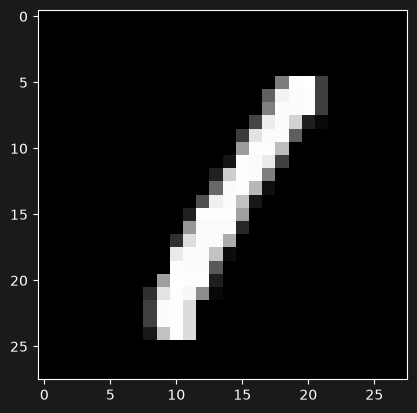

Label: 1


In [23]:
plt.imshow(image, cmap='gray')
plt.show()
print(f'Label: {label}')

In [24]:
train_loader = torch.utils.data.DataLoader(
    dataset=mnist_train,
    batch_size=100,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    dataset=mnist_test,
    batch_size=100,
    shuffle=False
)

In [25]:
data_train_iter = iter(train_loader)
images, labels = next(data_train_iter)
print(images.shape)
print(labels.shape)

torch.Size([100, 1, 28, 28])
torch.Size([100])


In [26]:
x = images.view(-1, 28*28)
print(x.shape)

torch.Size([100, 784])


$$
y_1 = \sum_ix_iw_{i, 1} + b_1
$$

$$
y =  zW + b
$$

In [27]:
W = torch.randn(784, 10) / np.sqrt(784) # Xavier initialization

$$
\sigma = \frac{1}{\sqrt{784}}
$$

[XE VS HE habr](https://habr.com/ru/articles/932852/)

[Xavier in geeksforgeeks](https://www.geeksforgeeks.org/deep-learning/xavier-initialization/)

[XE vs HE medium](https://medium.com/thedeephub/he-and-xavier-weight-initialization-functions-acedc5322ce5)


In [28]:
W.requires_grad = True
b = torch.zeros(10, requires_grad=True)
W, b

(tensor([[ 0.0201,  0.0172, -0.0171,  ..., -0.0374,  0.0642,  0.0240],
         [ 0.0627, -0.0743, -0.0093,  ..., -0.0139, -0.0441, -0.0231],
         [-0.0102,  0.0320, -0.0570,  ..., -0.0249, -0.0419,  0.0167],
         ...,
         [-0.0187, -0.0271, -0.0707,  ..., -0.0238, -0.0110,  0.0269],
         [-0.0033,  0.0252, -0.0658,  ...,  0.0216,  0.0182, -0.0682],
         [-0.0218,  0.0790, -0.0267,  ...,  0.0326,  0.0482,  0.0364]],
        requires_grad=True),
 tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True))

# Forward propagation
$$
y = xW + b
$$

In [29]:
y = torch.matmul(x, W) + b # x @ W + b
print(y[0, :])

tensor([ 0.0771,  0.1804, -0.3631, -0.0607,  0.1531,  0.4092, -0.5165, -0.2472,
        -0.3853,  0.6506], grad_fn=<SelectBackward0>)


# Softmax

$$
P_i = \frac{e^{z_i}}{\sum_{j=1}^{10}e^{z_j}}
$$

In [30]:
# py_eq = torch.exp(y)/torch.sum(torch.exp(y), dim=1, keepdim=True)
# print(py_eq[0])

tensor([0.1023, 0.1134, 0.0659, 0.0891, 0.1104, 0.1426, 0.0565, 0.0740, 0.0644,
        0.1815], grad_fn=<SelectBackward0>)


In [31]:
py = F.softmax(y, dim=1)
print(py[0])

tensor([0.1023, 0.1134, 0.0659, 0.0891, 0.1104, 0.1426, 0.0565, 0.0740, 0.0644,
        0.1815], grad_fn=<SelectBackward0>)
